In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

In [ ]:
df = pd.read_csv('superstore_orders.csv')
df.head(5)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


### Choose the Features

In [4]:
features = ['Sales', 'Quantity', 'Discount', 'Profit']
X = df[features]

In [5]:
X.shape

(10194, 4)

### Run Isolation Forest

In [7]:
model = IsolationForest(contamination=0.02, random_state=42)
df['anomaly'] = model.fit_predict(X)

df['anomaly'].value_counts()

anomaly
 1    9990
-1     204
Name: count, dtype: int64

### Flagged Orders

In [8]:
anomalies = df[df['anomaly'] == -1]
print('Flagged', len(anomalies), 'orders out of', len(df))
# the most extreme ones, by size of profit or loss

anomalies.reindex(
    anomalies['Profit'].abs().sort_values(ascending=False).index
)[['Sales','Quantity','Discount','Profit','Sub-Category']].head(10)

Flagged 204 orders out of 10194


,Sales,Quantity,Discount,Profit,Sub-Category
5894,17499.950,5,0.0,8399.9760,Copiers
7255,13999.960,4,0.0,6719.9808,Copiers
6398,4499.985,5,0.7,-6599.9780,Machines
9517,10499.970,3,0.0,5039.9856,Copiers
6674,9892.740,13,0.0,4946.3700,Binders
1203,9449.950,5,0.0,4630.4755,Binders
9171,11199.968,4,0.2,3919.9888,Copiers
9318,7999.980,4,0.5,-3839.9904,Machines
821,2177.584,8,0.8,-3701.8928,Binders
7441,2549.985,5,0.7,-3399.9800,Machines


### Normal vs Anomalous Orders

In [9]:
df.groupby('anomaly')[features].mean()

,Sales,Quantity,Discount,Profit
anomaly,,,,
-1,2883.152927,6.607843,0.275196,320.804777
1,174.011127,3.734334,0.152938,22.707972


### Visualize anomalies

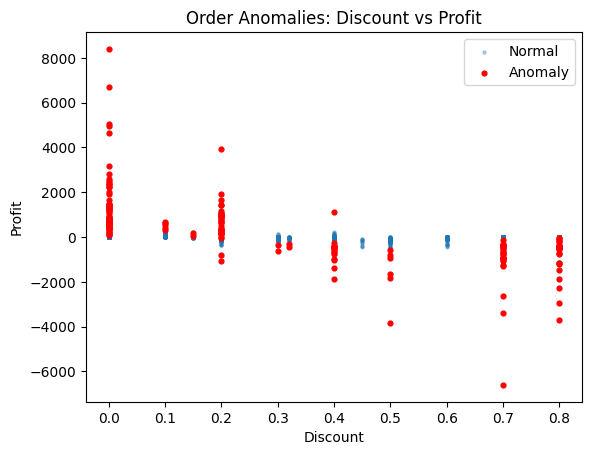

In [11]:
normal = df[df['anomaly'] == 1]
plt.scatter(normal['Discount'], normal['Profit'],
            s=5, alpha=0.3, label='Normal')

plt.scatter(anomalies['Discount'], anomalies['Profit'],
            s=12, color='red', label='Anomaly')

plt.title('Order Anomalies: Discount vs Profit')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.legend()
plt.show()